Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset: /content/drive/MyDrive/Housing.csv
Dataset shape: (545, 13)
Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']
Number of original features: 12

Number of encoded features: 13
Encoded features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']
Training samples: 436
Validation samples: 109

LEARNING RATE = 0.1
Epoch  500 | Training MSE = 968358188440.724 | Validation MSE = 1754318687330.669 | Validation R2 = 0.652924
Epoch 1000 | Training MSE = 968358188440.724 | Validation MSE = 1754318687330.669 | Validation R2 = 0.652924
Epoch 1500 | Training MSE = 968358188440.724 | Valid

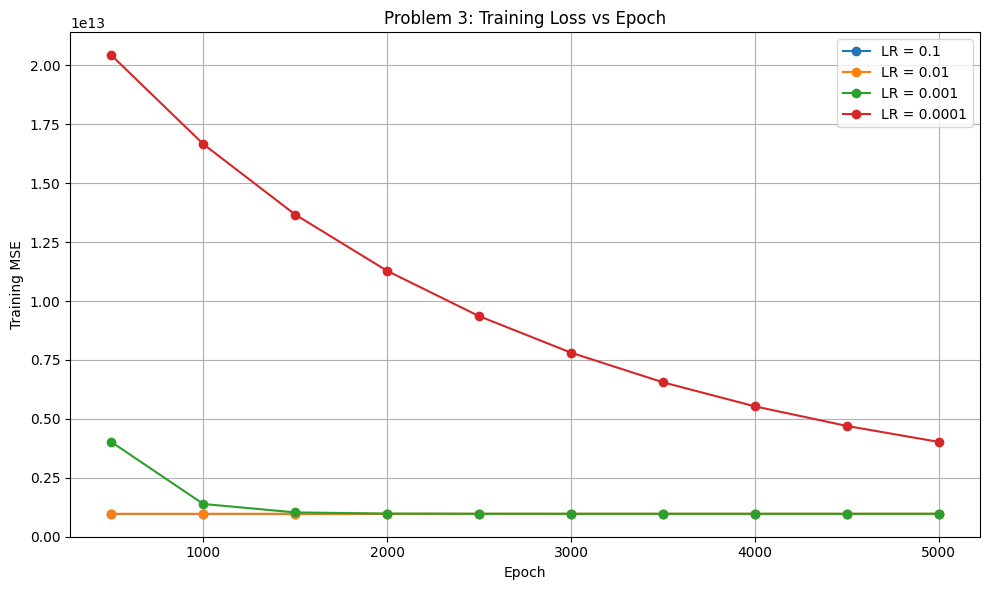

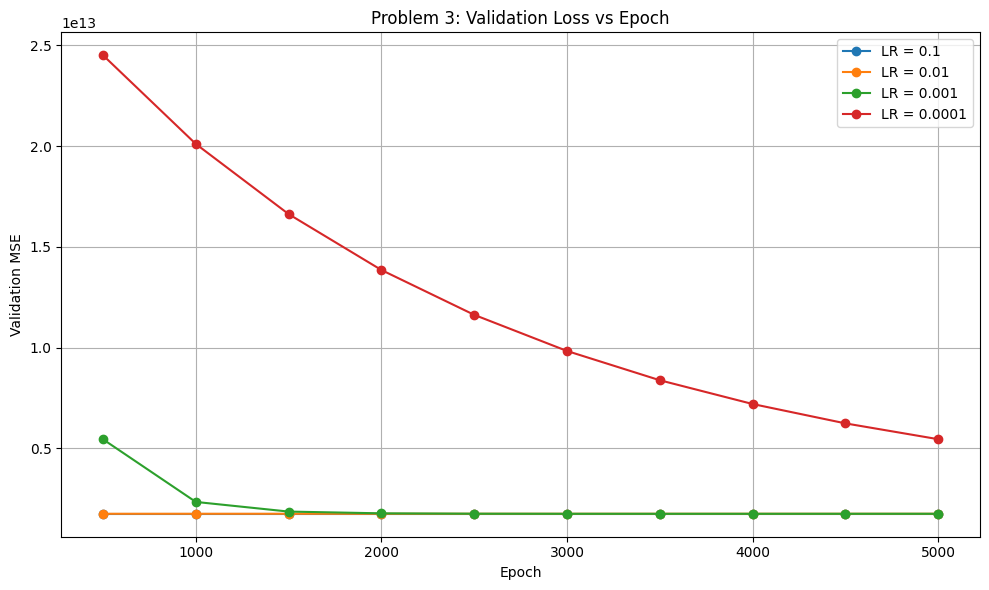

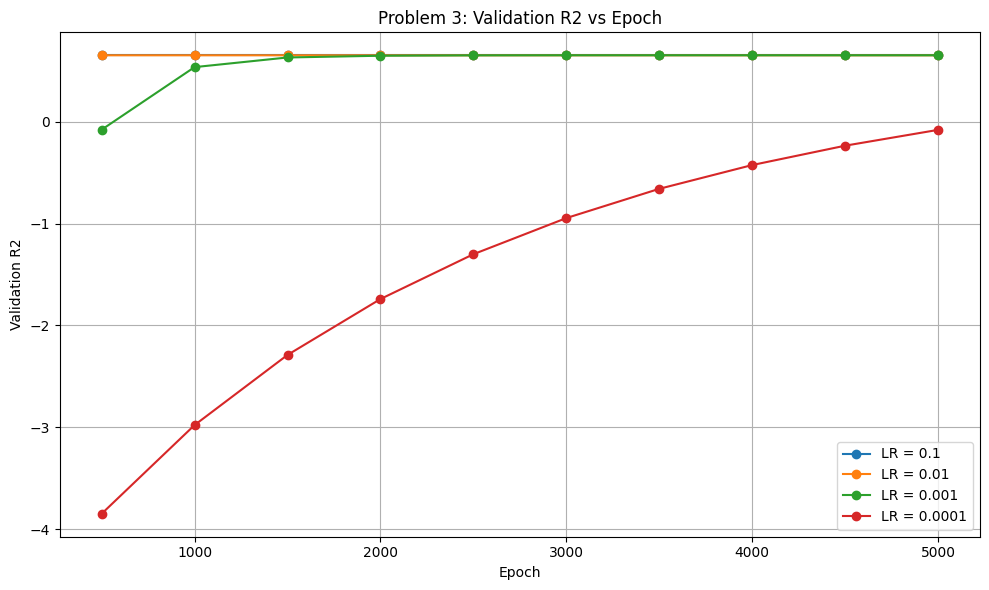


PROBLEM 3(c): PROBLEM 2 VS PROBLEM 3
                    Model  Training MSE  Validation MSE  Validation R2
Problem 2 - Five Features  1.350008e+12    2.292722e+12       0.546406
 Problem 3 - All Features  9.683653e+11    1.753788e+12       0.653029

Validation MSE Improvement: 23.51%

PROBLEM 3(c): HOMEWORK 2 VS HOMEWORK 5
                    Model  Training Loss (Half-MSE)  Validation Loss (Half-MSE)
 Homework 2 - 11 Features              4.962445e+11                9.001114e+11
Homework 5 - All Features              4.841826e+11                8.768941e+11

Validation Loss Difference: 2.58%


In [2]:

# ============================================================
# HOMEWORK 5 - PROBLEM 3 (a, b, c)
# Linear Regression Using ALL Housing Features
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# ============================================================
# Problem 3(a): Load and preprocess housing dataset
# ============================================================

drive.mount('/content/drive')

housing_path = None

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower() in ['housing.csv', 'housing(2).csv']:
            housing_path = os.path.join(root, file)
            break
    if housing_path is not None:
        break

if housing_path is None:
    raise FileNotFoundError("Housing.csv not found in Google Drive.")

df = pd.read_csv(housing_path)

target = 'price'
features = [col for col in df.columns if col != target]

print("Dataset:", housing_path)
print("Dataset shape:", df.shape)
print("Features:", features)
print("Number of original features:", len(features))

X = df[features].copy()
y = df[target].copy()

# Same train-validation split as Problem 2
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Encode binary categorical variables
binary_columns = [
    'mainroad', 'guestroom', 'basement',
    'hotwaterheating', 'airconditioning', 'prefarea'
]

for col in binary_columns:
    X_train[col] = X_train[col].map({'yes': 1, 'no': 0})
    X_val[col] = X_val[col].map({'yes': 1, 'no': 0})

# One-hot encode furnishing status.
# Drop one category to avoid redundant parameters.
X_train = pd.get_dummies(
    X_train,
    columns=['furnishingstatus'],
    drop_first=True,
    dtype=float
)

X_val = pd.get_dummies(
    X_val,
    columns=['furnishingstatus'],
    drop_first=True,
    dtype=float
)

# Ensure validation columns match training columns
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)

# Convert all features to float
X_train = X_train.astype(float)
X_val = X_val.astype(float)

if X_train.isnull().any().any() or X_val.isnull().any().any():
    raise ValueError("Missing or unrecognized categorical values found.")

feature_names = X_train.columns.tolist()

print("\nNumber of encoded features:", len(feature_names))
print("Encoded features:", feature_names)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

# Standardize input features using training statistics
mean = X_train.mean()
std = X_train.std(ddof=0).replace(0, 1)

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std

# Scale target during optimization
price_scale = 1_000_000.0

y_train = y_train / price_scale
y_val = y_val / price_scale

# Convert to PyTorch tensors
X_train = torch.tensor(
    X_train.to_numpy(), dtype=torch.float64
)
X_val = torch.tensor(
    X_val.to_numpy(), dtype=torch.float64
)

y_train = torch.tensor(
    y_train.to_numpy(), dtype=torch.float64
)
y_val = torch.tensor(
    y_val.to_numpy(), dtype=torch.float64
)


# ============================================================
# Problem 3(a): Linear model and training loop
# ============================================================

# Generalized linear model: one weight per encoded feature
# plus one bias parameter.

def model(X, params):
    weights = params[:-1]
    bias = params[-1]
    return X @ weights + bias


def loss_fn(y_pred, y_true):
    squared_diffs = (y_pred - y_true)**2
    return squared_diffs.mean()


def training_loop(n_epochs, learning_rate, params,
                  X_train, y_train, X_val, y_val):

    history = []

    for epoch in range(1, n_epochs + 1):

        if params.grad is not None:
            params.grad.zero_()

        train_pred = model(X_train, params)
        loss = loss_fn(train_pred, y_train)

        loss.backward()

        with torch.no_grad():
            params -= learning_rate * params.grad

        if epoch % 500 == 0:

            with torch.no_grad():
                train_pred = model(X_train, params)
                val_pred = model(X_val, params)

                train_mse = loss_fn(
                    train_pred, y_train
                ).item() * price_scale**2

                val_mse = loss_fn(
                    val_pred, y_val
                ).item() * price_scale**2

                val_r2 = r2_score(
                    y_val.numpy(),
                    val_pred.numpy()
                )

            history.append({
                'Epoch': epoch,
                'Training MSE': train_mse,
                'Validation MSE': val_mse,
                'Validation R2': val_r2
            })

            print(
                f"Epoch {epoch:4d} | "
                f"Training MSE = {train_mse:.3f} | "
                f"Validation MSE = {val_mse:.3f} | "
                f"Validation R2 = {val_r2:.6f}"
            )

    return params.detach().clone(), pd.DataFrame(history)


# ============================================================
# Problem 3(b): Four training sessions, 5000 epochs each
# ============================================================

learning_rates = [0.1, 0.01, 0.001, 0.0001]

results = {}

n_params = X_train.shape[1] + 1

for lr in learning_rates:

    print("\n" + "=" * 65)
    print(f"LEARNING RATE = {lr}")
    print("=" * 65)

    params = torch.zeros(
        n_params,
        dtype=torch.float64,
        requires_grad=True
    )

    final_params, history = training_loop(
        n_epochs=5000,
        learning_rate=lr,
        params=params,
        X_train=X_train,
        y_train=y_train,
        X_val=X_val,
        y_val=y_val
    )

    results[lr] = {
        'params': final_params,
        'history': history,
        'train_mse': history.iloc[-1]['Training MSE'],
        'val_mse': history.iloc[-1]['Validation MSE'],
        'val_r2': history.iloc[-1]['Validation R2']
    }


# ============================================================
# Problem 3(b): Final results and best model
# ============================================================

summary = pd.DataFrame([
    {
        'Learning Rate': lr,
        'Training MSE': results[lr]['train_mse'],
        'Validation MSE': results[lr]['val_mse'],
        'Validation R2': results[lr]['val_r2']
    }
    for lr in learning_rates
])

print("\nFINAL RESULTS FOR ALL LEARNING RATES")
print(summary.to_string(index=False))

# Best model based on lowest validation MSE
best_lr = min(
    learning_rates,
    key=lambda lr: results[lr]['val_mse']
)

best = results[best_lr]
best_params = best['params']

print("\n" + "=" * 65)
print("BEST LINEAR REGRESSION MODEL - ALL FEATURES")
print("=" * 65)

print("Best Learning Rate:", best_lr)
print(f"Training MSE: {best['train_mse']:.3f}")
print(f"Validation MSE: {best['val_mse']:.3f}")
print(f"Validation R2: {best['val_r2']:.6f}")


# ============================================================
# Problem 3(a): Best parameters in original units
# ============================================================

scaled_weights = best_params[:-1].numpy()
scaled_bias = best_params[-1].item()

original_weights = (
    price_scale * scaled_weights / std.to_numpy()
)

original_bias = price_scale * (
    scaled_bias -
    np.sum(
        scaled_weights * mean.to_numpy() / std.to_numpy()
    )
)

print("\nBEST MODEL PARAMETERS (ORIGINAL UNITS)")

for name, weight in zip(feature_names, original_weights):
    print(f"{name:30s}: {weight:.6f}")

print(f"{'bias':30s}: {original_bias:.6f}")


# ============================================================
# Problem 3(b): Training loss plot
# ============================================================

plt.figure(figsize=(10, 6))

for lr in learning_rates:
    h = results[lr]['history']

    plt.plot(
        h['Epoch'],
        h['Training MSE'],
        marker='o',
        label=f"LR = {lr}"
    )

plt.xlabel('Epoch')
plt.ylabel('Training MSE')
plt.title('Problem 3: Training Loss vs Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# Problem 3(b): Validation loss plot
# ============================================================

plt.figure(figsize=(10, 6))

for lr in learning_rates:
    h = results[lr]['history']

    plt.plot(
        h['Epoch'],
        h['Validation MSE'],
        marker='o',
        label=f"LR = {lr}"
    )

plt.xlabel('Epoch')
plt.ylabel('Validation MSE')
plt.title('Problem 3: Validation Loss vs Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# Problem 3(b): Validation R2 plot
# ============================================================

plt.figure(figsize=(10, 6))

for lr in learning_rates:
    h = results[lr]['history']

    plt.plot(
        h['Epoch'],
        h['Validation R2'],
        marker='o',
        label=f"LR = {lr}"
    )

plt.xlabel('Epoch')
plt.ylabel('Validation R2')
plt.title('Problem 3: Validation R2 vs Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# Problem 3(c): Compare with Problem 2
# ============================================================

# Homework 5 Problem 2 results (same random seed/split)
p2_train_mse = 1350008211326.580
p2_val_mse = 2292721545725.367
p2_val_r2 = 0.546406

comparison_p2 = pd.DataFrame({
    'Model': [
        'Problem 2 - Five Features',
        'Problem 3 - All Features'
    ],
    'Training MSE': [
        p2_train_mse,
        best['train_mse']
    ],
    'Validation MSE': [
        p2_val_mse,
        best['val_mse']
    ],
    'Validation R2': [
        p2_val_r2,
        best['val_r2']
    ]
})

print("\n" + "=" * 65)
print("PROBLEM 3(c): PROBLEM 2 VS PROBLEM 3")
print("=" * 65)

print(comparison_p2.to_string(index=False))

p2_improvement = (
    (p2_val_mse - best['val_mse']) / p2_val_mse
) * 100

print(f"\nValidation MSE Improvement: {p2_improvement:.2f}%")


# ============================================================
# Problem 3(c): Compare with Homework 2
# ============================================================

# Homework 2: 11-feature standardized model
# Reported loss assumed to be half-MSE
hw2_train_loss = 496244544318.542
hw2_val_loss = 900111363844.019

# Convert HW5 MSE to half-MSE for comparison
hw5_train_half_mse = best['train_mse'] / 2
hw5_val_half_mse = best['val_mse'] / 2

comparison_hw2 = pd.DataFrame({
    'Model': [
        'Homework 2 - 11 Features',
        'Homework 5 - All Features'
    ],
    'Training Loss (Half-MSE)': [
        hw2_train_loss,
        hw5_train_half_mse
    ],
    'Validation Loss (Half-MSE)': [
        hw2_val_loss,
        hw5_val_half_mse
    ]
})

print("\n" + "=" * 65)
print("PROBLEM 3(c): HOMEWORK 2 VS HOMEWORK 5")
print("=" * 65)

print(comparison_hw2.to_string(index=False))

hw2_improvement = (
    (hw2_val_loss - hw5_val_half_mse) / hw2_val_loss
) * 100

print(f"\nValidation Loss Difference: {hw2_improvement:.2f}%")

